Author: Erik Lamb

Date: 12/30/2024

Description:
This notebook preprocesses the XPCS scans by loading and cropping the images, fitting the peaks in X and Y and extracting, creating the Q-maps, and by extracting relevant information that is currently scattered between the .batchinfo files and the hdf5 files. This will output an easily readable .npz file containing all of this information for ease of analysis across other notebooks, such as xpcs and cross_correlations. Those notebooks will first check that such a file exists before beginning analysis. This is written as a notebook rather than a function because I believe it is important to visually check the data reduction is performed correctly. 

To Do:
Use 2D Gaussian fits with skewness and tilt to fit the peak instead. Save those parameters. Apply a Gaussian filter prior to fitting too. Rerun for temps up until 385

In [1]:
import sys
sys.path.append('../src/')
from xpcs import *
from autocorrelations import *
import cv2
from scipy.special import erfinv
from scipy.special import erf
import pyopencl as cl
from pathlib import Path
import json
import tqdm as tqdm



%matplotlib widget


In [20]:
### User Defined
### This should be the only thing that needs to defined
CONFIG_FILE_NAME = "config_NPS_example.json"#"config_IPA_NBH_A4_data_113025.json" # #"config_B10_2_A7_data_091825.json" #"config_NPS_2_data_090825.json" #"config_B10_2_A7_data_071525.json"

### Scan In Config You Want to PreProcess ### 
Scan = "219"


# User Defined Parameters

In [3]:
### Analysis Parameters ###

#Crop Size
#number of standard deviations from peak
Xv = 0
Xh = 0

row_crop = 1400
col_crop = 1000

sigma_crop = False

stability = True

New_Mask = True



# Config File Loaded Parameters

In [4]:
### Open Config File ###
# Define the path to the configuration file
config_file = Path('../configs/'+CONFIG_FILE_NAME)

# Open and load the JSON configuration file
with open(config_file, "r") as file:
    config = json.load(file)

### Output Directory ###
figure_path = config_file.parent.parent / config.get("Figures")
fig_path = figure_path / str(Scan)

if not os.path.exists(fig_path):
    os.makedirs(fig_path)
    if os.path.exists(fig_path):
        print(f"Directory '{fig_path}' created!")

### Load Work Paths ###
BASE_DIR      = Path(config.get("Base"))
dataset_path  = Path(config.get(str(Scan)))
work_path     = BASE_DIR / dataset_path 


### Import Beamline Parameters ###
### Not user defined ###
Beamline      = config.get("Beamline") #P10 or 8IDE
Geometry      = config.get("Geometry") #Horizontal or Vertical
Compound      = config.get("Compound")
Particle      = config.get("Particle") #2,3, A7
#Temperature   = int(config.get(str(Scan)+"T")) #Picks out temp from config file
#Temperature is scraped from filename

#Temperature Handled Differently
if 'B10' in CONFIG_FILE_NAME:
    Temperature = float(str(dataset_path)[21:27])/1000 #Temperature in Kelvin
if 'NBH' in CONFIG_FILE_NAME:
    Temperature = float(str(dataset_path)[23:26]) #Temperature in Kelvin
if 'NPS' in CONFIG_FILE_NAME:
    Temperature = float(config.get(f"{Scan}_temperature")) #Temperature in Kelvin

### Defined Processed Paths ###
processed_path = work_path / 'processed'
processed = processed_path / f'{Compound}_particle{Particle}_temp{Temperature}K_crop{Xv}x{Xh}_NewMask{New_Mask}_stability{stability}.h5'




#Check that Path exists and contents of Path
if work_path.exists():
    print(f'Directory found: {work_path}')
else:
    print(f'Directory not found: {work_path}')

#Load File Names
file_list = np.sort(os.listdir(work_path)).tolist()

#Remove first element if it's DS_Store
if file_list[0] == '.DS_Store':
    file_list.remove(file_list[0])

#Removes strange file that occurs if you edit batchinfo
if file_list[0][0:2] == '._':
    file_list.remove(file_list[0])

print('Contains:') 
for f in file_list:
    print(f)

Directory found: /Users/eriklamb/data/PETRA/PETRA_P10_November2023/Beamtime_11017686/raw/NPS_01_00219/e4m
Contains:
NPS_01_00219.batchinfo
NPS_01_00219_data_000001.h5
NPS_01_00219_master.h5
mask219.mat
processed
results
speckle_fwhm_scan219.npz


# Extract Beamline Parameters

In [5]:
### This can written as a function to remove clutter ###

if Beamline == '8IDE_2025_2' or Beamline == '8IDE_2025_3':
    
    batchinfo = load_batchinfo(work_path / file_list[1],'=') # batchinfo contains other parameters

    #Load Parameters From batchinfo

    
    ### The Following Were Manually Loaded!!! Inform Suresh/Eric these are necessary for Q-Map!!! ###
    energy     = batchinfo['energy'] #keV
    wavelength = kev_to_angstroms(energy)
    ttheta     = batchinfo['tth'] ### Not Loaded!!!
    pixelSize  = batchinfo['pixel_size'] #mm
    X0         = batchinfo['bcx'] #Pixels
    Y0         = batchinfo['bcy'] #Pixels


    ### I am unsure if these are right ###
    frame_spacing = batchinfo['preset']
    D          = batchinfo['rr'] #sample to detector distance

    ### These are right as usual ###
    #ccdz = batchinfo['ccdz'] #note, this is eta. Naming is ccdz for consistency with PETRA
    horBeg     = batchinfo['col_beg']
    horEnd     = batchinfo['col_end']
    verBeg     = batchinfo['row_beg']
    verEnd     = batchinfo['row_end']
    samx       = batchinfo['samx'] #this is mislabeled in the batchinfo. Actually samy
    samz       = batchinfo['samz']
    detDims    = np.array([[horBeg, horEnd],[verBeg,verEnd]]) 
    
    ### Load Data ###
    data      = h5py.File(work_path / file_list[0], 'r')
    
    try:
        det = np.array(data['entry/data/data/'])[:,:,:] #Used for preprocessing
        det_corr = np.copy(det) #Used for g2 correlations
    finally:
        data.close()
    
    
if Beamline == '8IDE':
    
    metadata  = h5py.File(work_path / file_list[2], 'r') # hdf file contains metadata for the measurement
    
    batchinfo = load_batchinfo(work_path / file_list[1],'=') # batchinfo contains other parameters
    
    data      = h5py.File(work_path / file_list[0], 'r')

    try:
        #Load parameters From hdf file
        frame_spacing = np.array(metadata['/entry/instrument/detector_1/acquire_period'])
        X0            = np.array(metadata['/entry/instrument/bluesky/metadata/bcx'])
        Y0            = np.array(metadata['/entry/instrument/bluesky/metadata/bcy'])
        pixelSize     = np.array(metadata['/entry/instrument/bluesky/metadata/pix_dim_x']) #mm
        D             = np.array(metadata['/entry/instrument/bluesky/metadata/det_dist']) #sample to detector distance
        energy        = np.array(metadata['/entry/instrument/bluesky/metadata/X_energy']) #keV
        wavelength    = 10*1.2398/energy # Å
        
        #print_h5_item(metadata) uncomment to print contents
    finally: 
        #Close h5 file
        metadata.close()
    
    #Load Parameters From batchinfo
    ttheta     = batchinfo['th'] 
    #ccdz = batchinfo['ccdz'] #note, this is eta. Naming is ccdz for consistency with PETRA
    horBeg     = batchinfo['col_beg']
    horEnd     = batchinfo['col_end']
    verBeg     = batchinfo['row_beg']
    verEnd     = batchinfo['row_end']
    samx       = batchinfo['samx'] #this is mislabeled in the batchinfo. Actually samy
    samz       = batchinfo['samz']
    detDims    = np.array([[horBeg, horEnd],[verBeg,verEnd]]) 
    
    try:
        det = np.array(data['entry/data/data/'])[:,:,:] #Used for preprocessing
        det_corr = np.copy(det) #Used for g2 correlations
    finally:
        data.close()
    
    #X0 = batchinfo['x0'] #horizontal beam position
    #Y0 = batchinfo['y0'] #vertical beam position
    
if Beamline == 'P10':
    
    metadata = h5py.File(work_path / file_list[2], 'r') # hdf file contains metadata for the measurement
    
    batchinfo = load_batchinfo(work_path / file_list[0],':') # batchinfo contains other parameters
    
    try:
        #Load Parameters From .h5 file
        frame_spacing=np.array(metadata['/entry/instrument/detector/frame_time']);
        wavelength = np.array(metadata['entry/instrument/beam/incident_wavelength']) #Wavelength [Å]
        x_pixel_size = np.array(metadata['entry/instrument/detector/x_pixel_size/']) # [m]
        pixelSize = x_pixel_size*10**3 # [mm]

        #print_h5_item(metadata) uncomment to print contents

    finally: 
        #Close h5 file
        metadata.close()

    #Load Parameters From batchinfo
    X0 = batchinfo['x0'] #horizontal beam position
    Y0 = batchinfo['y0'] #vertical beam position
    ttheta = batchinfo['ccdtth'] #Detector posistion [deg]
    ccdz = batchinfo['ccdz']
    ccdz0 = batchinfo['ccdz0']
    D = batchinfo['rr'] # Sample to detector [mm]
    horBeg = batchinfo['col_beg']
    horEnd = batchinfo['col_end']
    verBeg = batchinfo['row_beg']
    verEnd = batchinfo['row_end']
    samy   = batchinfo['samx'] #this is mislabeled in the batchinfo. Actually samy
    samz   = batchinfo['samz']
    samth  = batchinfo['samth']
    detDims = np.array([[horBeg, horEnd],[verBeg,verEnd]]) 
    
    det = np.array(h5py.File(work_path / file_list[2], 'r')['entry/data/data_000001/'])[:,:,:] #Used for preprocessing
    det_corr = np.copy(det) #Used for g2 correlations



#Remove hot pixels
det[det>10000] = 0 

# Plot Speckles

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


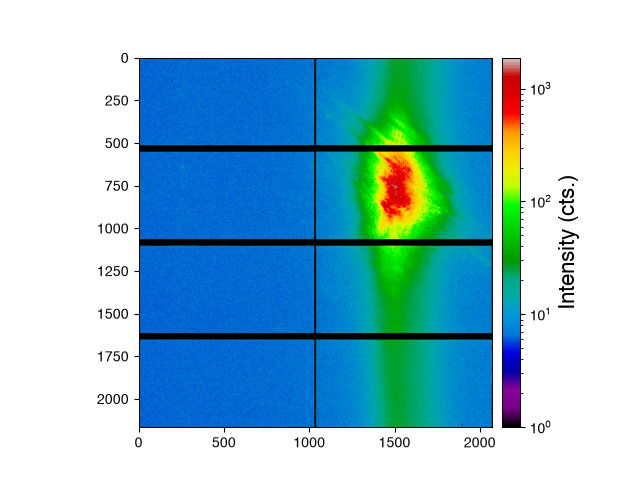

In [6]:

plt.rcParams['font.sans-serif'] = ['Helvetica']
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['axes.linewidth'] = 0.75   # spines, was implicitly ~1.4 at 8in

### Plotting ###
fig, ax = plt.subplots()

im = ax.imshow(np.sum(det[:,:,:],axis=0)+1e-6,cmap='nipy_spectral',norm=LogNorm(vmin=1, vmax=np.sum(det[:,:,:],axis=0).max()))

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("Intensity (cts.)",fontsize=16)
#ax.axes.xaxis.set_visible(False)
#ax.axes.yaxis.set_visible(False)
#plt.savefig(fig_path / f'{Scan}_speckle.png')
fig.savefig(figure_path / "detector_bragg_powder_ring.pdf", format="pdf", bbox_inches="tight")


# Fit Peak with 1D Gaussian

In [6]:
#Central Slice
#central_slice = det.shape[0]//2

### Sum data along both axes for fitting ###
y1 = np.sum(np.mean(det[:,:,:],axis=0),axis=0)
x1 = np.arange(y1.shape[0])

y2 = np.sum(np.mean(det[:,:,:],axis=0),axis=1)
x2 = np.arange(y2.shape[0])

popt1, pcov1 = curve_fit(gaussian, x1, y1, p0=[np.max(y1), np.where(y1==np.max(y1))[0][0], 50, np.min(y1[np.nonzero(y1)])])
#popt1, pcov1 = curve_fit(gaussian, x1, y1, p0=[np.max(y1), 800, 100, np.min(y1[np.nonzero(y1)])])
popt2, pcov2 = curve_fit(gaussian, x2, y2, p0=[np.max(y2), np.where(y2==np.max(y2))[0][0], 50, np.min(y2[np.nonzero(y2)])])
#popt2, pcov2 = curve_fit(gaussian, x2, y2, p0=[np.max(y2), 400 , 1, np.min(y2[np.nonzero(y2)])])

### Plotting ###
import matplotlib.pyplot as plt
%matplotlib notebook

# Create a figure and a set of subplots
fig, axs = plt.subplots(2, 1, figsize=(8, 4))  # 2 rows, 1 column

# Plot on the first axis
axs[0].plot(y1)
axs[0].plot(x1, gaussian(x1, *popt1), label='mu={}\nsigma={}'.format(popt1[1],popt1[2]), color='red')
axs[0].set_title('Q_x')
axs[0].legend()

# Plot on the second axis
axs[1].plot(y2)
axs[1].plot(x2, gaussian(x2, *popt2), label='mu={}\nsigma={}'.format(popt2[1],popt2[2]), color='red')
axs[1].set_title('Q_y')
axs[1].legend()

# Adjust layout
plt.tight_layout()

# Show the plot
plt.show()

plt.savefig(fig_path / f'{Scan}_fit.png', dpi=150)

<IPython.core.display.Javascript object>

# Fit Peak with 2D Gaussian

In [7]:
#Sum the Images for fitting
#det_sum = np.mean(det,axis=0)
det_sum = np.sum(det[0:5,:,:],axis=0)

#Find the x and y lengths of array. Note indices are flipped
xLen = det_sum.shape[1]
yLen = det_sum.shape[0]

#Create XY coordinates
x = np.arange(xLen)
y = np.arange(yLen)
x, y = np.meshgrid(x, y)

# Find the index of the maximum value
max_index = np.argmax(det_sum)
row_max, col_max = np.unravel_index(max_index, det_sum.shape)

#Initial Guess for Fits
std_col = 70 #Standard Deviation in X
std_row = 130 #Standard Deviation in Y
tilt = 0 #Angular tilt of distribution in radians

if Particle==2 and Temperature==345 and Scan==579:
    col_max = 1536
    row_max = 707

#Create initial guess array from prior fitting, cropped dataset
initial_guess = [np.max(det_sum),popt1[1],popt2[1],popt1[2],popt2[2],tilt,np.min(det_sum[np.nonzero(det_sum)])]

#Fit Data and Calculate 2D Gaussian
popt, pcov = fit_gaussian_2d(det_sum,initial_guess)
data_fitted = gaussian_2d((x, y), *popt).reshape(det_sum.shape)

print(f'Gaussian Fit Parameters\nA: {popt[0]},\nCol: {popt[1]},\nRow: {popt[2]},\nStdX: {popt[3]},\nStdY: {popt[4]},\nTilt: {popt[5]},\nBG: {popt[6]}')
#Plotting

Gaussian Fit Parameters
A: 8.11573712604005,
Col: 1510.9675435633922,
Row: 754.2650528912353,
StdX: 58.731524028777926,
StdY: 123.92947891433192,
Tilt: 0.027665296301496087,
BG: 0.06875271007281647


In [8]:
fig, ax = plt.subplots()

ax.imshow(det_sum+1e-6, cmap='nipy_spectral',norm=LogNorm(vmin=1, vmax=det_sum.max()))
ax.contour(x,y,data_fitted, 5, colors='w')
plt.title('2D Gaussian Fit')
plt.show()
plt.savefig(fig_path / f'{Scan}_fit_2d.png', dpi=150)

<IPython.core.display.Javascript object>

# Extract Mask Dimensions

In [9]:
if New_Mask == False:
    with h5py.File(mask_path, 'r') as DATA:
        mask = DATA['XPCS/Mask'][:]

# Crop Image

In [10]:
#Peak Locations
hCen = int(np.rint(popt1[1]))
vCen = int(np.rint(popt2[1]))

#hCen = int(np.rint(popt[1]))
#vCen = int(np.rint(popt[2]))

#Standard Deviations
hSig = int(np.rint(popt1[2]))
vSig = int(np.rint(popt2[2]))

#hSig = int(np.rint(popt[3]))
#vSig = int(np.rint(popt[4]))

angTilt = popt[5] #tilt in the distribution


#Set ROI
if New_Mask == True:
    if sigma_crop == True:
        roi = [int(vCen-Xv*vSig),int(vCen+Xv*vSig),int(hCen-Xh*hSig),int(hCen+Xh*hSig)] #vertical_1, vertical_2, horizontal_1, horizontal_2
    if sigma_crop == False:
        roi = [int(vCen-row_crop//2),int(vCen+row_crop//2),int(hCen-col_crop//2),int(hCen+col_crop//2)] #vertical_1, vertical_2, horizontal_1, horizontal_2
if New_Mask == False:
        roi = [int(vCen-mask.shape[1]//2),int(vCen+mask.shape[1]//2),int(hCen-mask.shape[2]//2),int(hCen+mask.shape[2]//2)] #vertical_1, vertical_2, horizontal_1, horizontal_2


#Take subset of detector
det_cropped = det[:,roi[0]:roi[1],roi[2]:roi[3]]
det_corr_cropped = det_corr[:,roi[0]:roi[1],roi[2]:roi[3]]

#ax.axes.xaxis.set_visible(False)
#ax.axes.yaxis.set_visible(False)

In [11]:
#Plot cropped image
fig, ax = plt.subplots(1,3,figsize = (15,5))

frame = 0

ax[0].imshow(det_cropped[0,:,:]+1e-6,cmap='nipy_spectral',norm=LogNorm(vmin=1, vmax=np.max(np.sum(det_cropped[0:5,:,:],axis=0)+1)))
ax[1].plot(det_cropped[frame,det_cropped.shape[1]//2,:],'b')
ax[2].plot(det_cropped[frame,:,det_cropped.shape[2]//2],'b')

ax[0].set_title(f"Frame = {frame}")
ax[1].set_title('Horizontal Cut')
ax[2].set_title('Vertical Cut')

plt.subplots_adjust(wspace=0.25, hspace=0.4)
plt.savefig(fig_path / f'{Scan}_cropped.png', dpi=150)


<IPython.core.display.Javascript object>

# Stability

In [12]:
divs = 5

seg  = det_cropped.shape[0]//divs

fig,axs = plt.subplots(1,2,figsize=(10,5))

for d in range(divs):
    axs[0].semilogy(np.sum(np.sum(det_cropped[d*seg:(d+1)*seg,:,:],axis=0),axis=0),label = f"{frame_spacing*d*seg}-{frame_spacing*(d+1)*seg}")
    axs[1].semilogy(np.sum(np.sum(det_cropped[d*seg:(d+1)*seg,:,:],axis=0),axis=1),label = f"{frame_spacing*d*seg}-{frame_spacing*(d+1)*seg}")

axs[0].legend()
axs[1].legend()

fig.suptitle(f'Scan {Scan} Stability')

plt.savefig(fig_path / f'{Scan}_stability_1.png', dpi=150)

<IPython.core.display.Javascript object>

# Stability Check

In [13]:
#Create initial guess array from prior fitting, cropped dataset
from typing import Any


initial_guess = popt #np.array([np.max(det[0,:,:]),det.shape[2]//2,det.shape[1]//2,hSig,vSig,angTilt,np.min(det[0,:,:][np.nonzero(det[0,:,:])])])

time_bin_size = 10 

det_time_binned = time_bin(det,time_bin_size,'sum')

t = frame_spacing*time_bin_size*np.arange(1,det_time_binned.shape[0]+1)


#Stores the optimaized parameters for all frames
POPT = np.zeros((det_time_binned.shape[0],initial_guess.shape[0]))
PCOV = np.zeros((det_time_binned.shape[0],initial_guess.shape[0]))

if stability == True:
    for t,im in zip(tqdm.tqdm(range(det_time_binned.shape[0])),det_time_binned):

        if t==0:
            #Fit Data and Calculate 2D Gaussian
            popt, pcov = fit_gaussian_2d(im,initial_guess)
        else:
            #Fit Data and Calculate 2D Gaussian
            popt, pcov = fit_gaussian_2d(im,POPT[t-1,:])

        POPT[t,:] += popt
        PCOV[t,:] += np.sqrt(np.diag(pcov))

100%|██████████| 90/90 [02:23<00:00,  1.60s/it]


In [14]:
t = frame_spacing*time_bin_size*np.arange(1,det_time_binned.shape[0]+1)

In [15]:
if stability == True:
    

    fig, ax = plt.subplots(2,2)
    fig.subplots_adjust(wspace=0.6, hspace=0.4)

    #Standard Deviations
    ax[0,0].plot(t,100*(POPT[:,3]-POPT[0,3])/POPT[0,3],'b',label='Major')
    ax[0,0].plot(t,100*(POPT[:,4]-POPT[0,4])/POPT[0,4],'r',label='Minor')
    ax[0,0].set_xlabel('t (s)')
    ax[0,0].set_ylabel('Sig %Δ')
    ax[0,0].legend()


    #Peak center
    ax[0,1].plot(t,100*(POPT[:,1]-POPT[0,1])/POPT[0,1],'b',label='Column')
    ax[0,1].plot(t,100*(POPT[:,2]-POPT[0,2])/POPT[0,2],'r',label='Row')
    ax[0,1].set_xlabel('t (s)')
    ax[0,1].set_ylabel('Center %Δ')
    ax[0,1].legend()


    #Intensity
    ax[1,0].plot(t,100*(POPT[:,0]-POPT[0,0])/POPT[0,0],'b',label='A')
    ax[1,0].plot(t,100*(POPT[:,-1]-POPT[0,-1])/POPT[0,-1],'r',label='BG')
    ax[1,0].set_xlabel('t (s)')
    ax[1,0].set_ylabel('Intensity %Δ')
    ax[1,0].legend()

    #Tilt
    ax[1,1].plot(t,100*(POPT[:,5]-POPT[0,5])/POPT[0,5],'b')
    ax[1,1].set_xlabel('t (s)')
    ax[1,1].set_ylabel('Tilt %Δ')


fig.suptitle(f'Scan {Scan} Stability')
plt.savefig(fig_path / f'{Scan}_stability_2.png', dpi=150)

<IPython.core.display.Javascript object>

# Waterfall Plot

In [16]:
fig, ax = plt.subplots(figsize=(5,5))

ax.imshow(det_cropped[:,:,det_cropped.shape[2]//2].T+1e-6,cmap='nipy_spectral',norm=LogNorm(vmin=1, vmax=det_cropped[:,:,det_cropped.shape[2]//2].max()))
ax.set_xlabel('time (s)')
plt.xticks(np.arange(0,det_cropped.shape[0]+1e-6,det_cropped.shape[0]//6), np.arange(0,det_cropped.shape[0]+1,det_cropped.shape[0]//6)*frame_spacing);


fig.suptitle(f'Scan {Scan} Row Waterfall')
plt.savefig(fig_path / f'{Scan}_waterfall.png', dpi=150)

<IPython.core.display.Javascript object>

# Make GIF

In [17]:
fps = 5
zoom = 2

# File Path Information
if not os.path.exists(processed_path):
    os.mkdir(processed_path)
    if os.path.exists(processed_path):
        print(f"Directory '{processed_path}' created!")
        
results_name = f'{Compound}_particle{Particle}_temp{Temperature}K_crop{Xv}x{Xh}_{fps}fps_NewMask{New_Mask}_right'
results = processed_path / results_name

#Plotting 
fig, ax = plt.subplots()

det_zoom = det_cropped[:,det_cropped.shape[1]//2-det_cropped.shape[1]//(2*zoom):det_cropped.shape[1]//2+det_cropped.shape[1]//(2*zoom),det_cropped.shape[2]//2-det_cropped.shape[2]//(2*zoom):det_cropped.shape[2]//2+det_cropped.shape[2]//(2*zoom)]
make_detector_movie(str(results), det_zoom+1e-6, np.arange(1,det_cropped.shape[0]), frame_spacing, fig, ax, fps, scale='log', clims = [1,0.5*det_zoom.max()])



<IPython.core.display.Javascript object>

# Calculate Q-Map

In [18]:
#Calculate shift in detector position in pixels, if any
#dpixz = int((ccdz-ccdz0)//pixelSize) #shift in pixels
#print(dpixz)

#Calculate momentum transfer in x and y directions
#qx,qy = reciprocal_space_map(wavelength,ttheta,X0,Y0-dpixz,pixelSize,D,detDims,Geometry)
qx,qy = reciprocal_space_map(wavelength,ttheta,X0,Y0,pixelSize,D,detDims,Geometry)


#Create a meshgrid to map to the detector shpae
Qx,Qy = np.meshgrid(qx,qy)

#Set to same ROI as the detector
Qx = Qx[roi[0]:roi[1],roi[2]:roi[3]]
Qy = Qy[roi[0]:roi[1],roi[2]:roi[3]]

## Check Q-Map calculation is correct

In [19]:
#TTH = q_to_tth(np.sqrt(Qx[det_cropped.shape[1]//2,:]**2+Qy[det_cropped.shape[1]//2,:]**2),wavelength)
if Geometry == 'Horizontal':
    TTH = q_to_tth(np.sqrt(Qx[det_cropped.shape[1]//2,:]**2+np.mean(Qy[:,:],axis=0)**2),wavelength)
    INT = np.sum(np.sum(det_cropped[:,:,:],axis=0),axis=0)
if Geometry == 'Vertical':
    TTH = q_to_tth(np.sqrt(Qx[:,det_cropped.shape[1]//2]**2+np.mean(Qy[:,:],axis=1)**2),wavelength)
    INT = np.sum(np.sum(det_cropped[:,:,:],axis=0),axis=1)

sig0 = 0.02 
alpha0 = 0

fitFunction = 'gaussian'

fig, ax = plt.subplots()

if fitFunction == 'skew_gaussian':
    lower_bounds = [-np.inf,-np.inf,-np.inf, -np.inf, 0]  # c >= 0
    upper_bounds = [np.inf, np.inf, np.inf,np.inf,np.inf]
    #popt, pcov = curve_fit(gaussian, TTH, INT, p0=[np.max(INT), TTH[np.argmax(INT)] , 0.05, np.min(INT[np.nonzero(INT)])])
    popt, pcov = curve_fit(skew_gaussian, TTH, INT, p0=[np.max(INT), TTH[np.argmax(INT)] , sig0,alpha0, np.min(INT[np.nonzero(INT)])],bounds=(lower_bounds, upper_bounds))
    ax.plot(TTH, skew_gaussian(TTH, *popt), label=f'mu={popt[1]}\nsigma={popt[2]}\nalpha={popt[3]}', color='red')

if fitFunction == 'gaussian':
    lower_bounds = [-np.inf,-np.inf,-np.inf, -np.inf]  # c >= 0
    upper_bounds = [np.inf, np.inf, np.inf,np.inf]
    popt, pcov = curve_fit(gaussian, TTH, INT, p0=[np.max(INT), TTH[np.argmax(INT)] , 0.01, np.min(INT[np.nonzero(INT)])])
    #popt, pcov = curve_fit(skew_gaussian, TTH, INT, p0=[np.max(INT), np.argmax(INT) , 1, np.min(y2[np.nonzero(y2)])],bounds=(lower_bounds, upper_bounds))
    ax.plot(TTH, gaussian(TTH, *popt), label=f'mu={popt[1]}\nsigma={popt[2]}', color='red')



ax.plot(TTH,INT,'b')
ax.set_xlabel('2Th (Degrees)')
ax.set_ylabel('Intensity')
ax.legend()


fig.suptitle(f'Scan {Scan} Peak')
plt.savefig(fig_path / f'{Scan}_qmap.png', dpi=150)

<IPython.core.display.Javascript object>

# Save Processed Data

In [22]:
#Check that path exists. Make a new one if it does not 
#Save as a compressed hdf5
if not os.path.exists(processed_path):
    os.mkdir(processed_path)
    if os.path.exists(processed_path):
        print(f"Directory '{processed_path}' created!")

if not os.path.exists(processed):
    # Save variables to the same HDF5 file
    with h5py.File(processed, 'w') as h5file:
        # Create groups
        group1 = h5file.create_group('data') #Cropped detector data
        group2 = h5file.create_group('experimental_parameters') #Information on scan/beamline parameters
        group3 = h5file.create_group('pre_processing') #Information calculated in preprocessing
        group4 = h5file.create_group('gaussian_fitting') #Results of frame by frame Gaussian fit
        
        
        # Create datasets for each variable
        group1.create_dataset('det', data=det_cropped, compression='gzip', compression_opts=9) #Cropped data with filter
        group1.create_dataset('det_corr', data=det_corr_cropped, compression='gzip', compression_opts=9) #Cropped data w/o filter

        group2.create_dataset('det_dimensions', data=detDims, compression='gzip', compression_opts=9)
        group2.create_dataset('frame_spacing', data=np.array([frame_spacing]), compression='gzip', compression_opts=9)
        group2.create_dataset('pixel_size', data=np.array([pixelSize]), compression='gzip', compression_opts=9)
        group2.create_dataset('sam_to_det', data=np.array([D]), compression='gzip', compression_opts=9) # 
        group2.create_dataset('ttheta', data=np.array([ttheta]), compression='gzip', compression_opts=9) #Detector two-theta
        group2.create_dataset('temperature', data=np.array([Temperature]), compression='gzip', compression_opts=9) #Detector two-theta
        group2.create_dataset('wavelength', data=np.array([wavelength]), compression='gzip', compression_opts=9)
        group2.create_dataset('X0', data=np.array([X0]), compression='gzip', compression_opts=9) #Beam center X position
        group2.create_dataset('Y0', data=np.array([Y0]), compression='gzip', compression_opts=9) #Beam center Y position
        group2.create_dataset('nFrames', data=np.array([det.shape[0]]), compression='gzip', compression_opts=9) #Number of frames
        group2.create_dataset('samz', data=np.array([samz]), compression='gzip', compression_opts=9) #Sample position z

        if Beamline=='P10':
            group2.create_dataset('samy', data=np.array([samy]), compression='gzip', compression_opts=9) #Sample position y
            group2.create_dataset('samth', data=np.array([samth]), compression='gzip', compression_opts=9) #Sample theta
        if Beamline=='8IDE':
            group2.create_dataset('samx', data=np.array([samx]), compression='gzip', compression_opts=9) #Sample position y

            
            
            
            
        group3.create_dataset('angular_tilt', data=np.array([angTilt]), compression='gzip', compression_opts=9) #Tilt in peak
        group3.create_dataset('hCen', data=np.array([hCen]), compression='gzip', compression_opts=9) #Horizontal center of peak
        group3.create_dataset('hSig', data=np.array([hSig]), compression='gzip', compression_opts=9) #Horizontal standard deviation
        group3.create_dataset('Qx', data=Qx, compression='gzip', compression_opts=9) #Reciprocal space map X coords
        group3.create_dataset('Qy', data=Qy, compression='gzip', compression_opts=9) #Reciprocal space map Y coords
        group3.create_dataset('vCen', data=np.array([vCen]), compression='gzip', compression_opts=9) #Vertical center of peak
        group3.create_dataset('vSig', data=np.array([vSig]), compression='gzip', compression_opts=9) #Vertical standard deviation
        
        group4.create_dataset('POPT', data=POPT, compression='gzip', compression_opts=9)
        group4.create_dataset('PCOV', data=PCOV, compression='gzip', compression_opts=9)
        group4.create_dataset('2D_time', data=t, compression='gzip', compression_opts=9)
        group4.create_dataset('TTH', data=TTH, compression='gzip', compression_opts=9)
        group4.create_dataset('INT', data=INT, compression='gzip', compression_opts=9)
        group4.create_dataset('popt', data=popt, compression='gzip', compression_opts=9)
        group4.create_dataset('pcov', data=pcov, compression='gzip', compression_opts=9)
        group4.create_dataset('popt1', data=popt1, compression='gzip', compression_opts=9)
        group4.create_dataset('popt2', data=popt2, compression='gzip', compression_opts=9)


        #group4.create_dataset('fit_function', data=np.array([fit_function]), compression='gzip', compression_opts=9)

        
    print(f"File {Compound}_particle{Particle}_temp{Temperature}K_crop{Xv}x{Xh}_NewMask{New_Mask}_stability{stability}.h5 saved!")

File NPS_particle2_temp298.0K_crop0x0_NewMaskTrue_stabilityTrue.h5 saved!
